# Nashville Airbnb Listings

**Goal:** clean the raw Inside Airbnb Nashville listings and analyze the factors that influence price.

**Steps**
1. Load & inspect
2. Drop duplicates / evaluate missing values
3. Fix data types
4. Parse text fields
5. Handle invalid values & outliers
6. Missing values
7. Feature engineering
8. Validate & export (`clean/listings_clean.csv`)
9. Visualizations: see any inherent trends
10. Predictors (X) and target (y = price)
11. Simple linear regression
12. Multiple linear regression
13. Takeaways

## 1. Load & inspect

In [1]:
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 100)

In [2]:
N_listing = pd.read_csv("data/Nashville_listings.csv")
print(N_listing.shape)

(10133, 90)


In [3]:
N_listing.info()

<class 'pandas.DataFrame'>
RangeIndex: 10133 entries, 0 to 10132
Data columns (total 90 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            10133 non-null  int64  
 1   listing_url                                   10133 non-null  str    
 2   scrape_id                                     10133 non-null  int64  
 3   last_scraped                                  10133 non-null  str    
 4   source                                        764 non-null    str    
 5   name                                          10133 non-null  str    
 6   description                                   10114 non-null  str    
 7   neighborhood_overview                         0 non-null      float64
 8   picture_url                                   10133 non-null  str    
 9   host_id                                       10133 non-null  int64  
 1

In [4]:
# Duplicate checks
print("Duplicate listing ids:", N_listing["id"].duplicated().sum())
print("Fully duplicated rows:", N_listing.duplicated().sum())

Duplicate listing ids: 0
Fully duplicated rows: 0


In [5]:
# Missing values, as % of rows
missing_pct = (N_listing.isnull().mean() * 100).round(1).sort_values(ascending=False)
missing_pct[missing_pct > 0]

neighborhood_overview           100.0
host_since                      100.0
host_response_time              100.0
host_thumbnail_url              100.0
host_acceptance_rate            100.0
host_response_rate              100.0
host_verifications              100.0
neighbourhood                   100.0
host_total_listings_count       100.0
host_neighbourhood              100.0
calendar_updated                100.0
instant_bookable                100.0
neighbourhood_group_cleansed    100.0
bathrooms                       100.0
source                           92.5
license                          88.4
host_about                       31.2
host_location                    23.2
review_scores_accuracy           12.8
first_review                     12.8
review_scores_checkin            12.8
review_scores_rating             12.8
reviews_per_month                12.8
review_scores_value              12.8
review_scores_cleanliness        12.8
review_scores_location           12.8
last_review 

## 2. Dropped columns

- **100% empty** — 17 columns contain no data at all in this export.
- **Redundant** — duplicates of another column 

In [6]:
empty_cols = N_listing.columns[N_listing.isnull().all()].tolist()
print(f"{len(empty_cols)} fully empty columns:", empty_cols)

14 fully empty columns: ['neighborhood_overview', 'host_since', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_thumbnail_url', 'host_neighbourhood', 'host_total_listings_count', 'host_verifications', 'neighbourhood', 'neighbourhood_group_cleansed', 'bathrooms', 'calendar_updated', 'instant_bookable']


In [7]:
metadata_cols = ["scrape_id", "last_scraped", "calendar_last_scraped", "source"]

url_and_raw_cols = [
    "listing_url", "picture_url", "host_url", "host_profile_url",
    "host_picture_url", "host_profile_id", "price_quote_raw",
]

redundant_cols = [
    "price_quote_price_per_night", "price_quote_total_price",
    "price_quote_checkin_date", "price_quote_checkout_date",
    "minimum_minimum_nights", "maximum_minimum_nights",
    "minimum_maximum_nights", "maximum_maximum_nights",
    "minimum_nights_avg_ntm", "maximum_nights_avg_ntm",
]

long_text_cols = ["description", "host_about"]

cols_to_drop = empty_cols + metadata_cols + url_and_raw_cols + redundant_cols + long_text_cols
df = N_listing.drop(columns=cols_to_drop).copy()
print(f"Columns: {N_listing.shape[1]} -> {df.shape[1]}")

Columns: 90 -> 53


## 3. Fix data types

In [8]:
# price is stored as text 
df["price"] = (
    df["price"]
    .str.replace(r"[$,]", "", regex=True)
    .astype(float)
)
df["price"].describe()

count     9319.000000
mean       383.158566
std        452.011942
min         25.840000
25%        189.020000
50%        296.710000
75%        433.150000
max      18708.000000
Name: price, dtype: float64

In [9]:
# Price Missing Values
missing_price = df["price"].isnull().sum()
missing_price_pct = (missing_price / len(df)) 
missing_price, missing_price_pct

(np.int64(814), np.float64(0.08033158985492944))

8% of the target model is missing not too bad for a dataset

In [10]:
df.dropna(subset=["price"], inplace=True)

In [11]:
missing_price = df["price"].isnull().sum()
missing_price

np.int64(0)

In [12]:
# Airbnb exports booleans as 't' / 'f'
bool_cols = ["host_is_superhost", "host_has_profile_pic", "host_identity_verified", "has_availability"]
for col in bool_cols:
    df[col] = df[col].map({"t": True, "f": False}).astype("boolean")  # nullable boolean keeps NaN
df[bool_cols].apply(lambda s: s.value_counts(dropna=False)).T

,False,True,<NA>
host_is_superhost,3505,5814,<NA>
host_has_profile_pic,62,9257,<NA>
host_identity_verified,118,9201,<NA>
has_availability,63,9254,2


In [13]:
for col in ["first_review", "last_review"]:
    df[col] = pd.to_datetime(df[col], errors="coerce")
for col in ["bedrooms", "beds", "minimum_nights", "maximum_nights"]:
    df[col] = df[col].astype("Int64")
df[["first_review", "last_review"]].describe()

,first_review,last_review
count,8197,8197
mean,2023-02-17 14:18:20.597779,2026-06-03 04:44:24.974990
min,2009-04-30 00:00:00,2015-08-16 00:00:00
25%,2021-06-20 00:00:00,2026-07-26 00:00:00
50%,2024-01-01 00:00:00,2026-08-30 00:00:00
75%,2025-08-18 00:00:00,2026-09-08 00:00:00
max,2026-09-20 00:00:00,2026-09-20 00:00:00


## 4. Parse messy text fields

**Bathrooms:** `bathrooms` is empty, but `bathrooms_text` has the info, e.g. `"2.5 baths"`, `"1 shared bath"`, `"Half-bath"`.
Split it into a numeric `bathrooms` count and a `bathroom_type` (private / shared).

In [14]:
def parse_bath_count(text):
    if pd.isna(text):
        return np.nan
    if "half-bath" in text.lower():
        return 0.5
    match = re.search(r"[\d.]+", text)
    return float(match.group()) if match else np.nan

def parse_bath_type(text):
    if pd.isna(text):
        return pd.NA
    return "shared" if "shared" in text.lower() else "private"

df["bathrooms"] = df["bathrooms_text"].apply(parse_bath_count)
df["bathroom_type"] = df["bathrooms_text"].apply(parse_bath_type)

# Spot-check every distinct input -> output mapping
df.groupby("bathrooms_text", dropna=False)[["bathrooms", "bathroom_type"]].first().sample(10, random_state=1)

,bathrooms,bathroom_type
bathrooms_text,,
7 baths,7.0,private
1 private bath,1.0,private
3.5 baths,3.5,private
6 private baths,6.0,private
4.5 private baths,4.5,private
3 shared baths,3.0,shared
47 baths,47.0,private
17.5 baths,17.5,private
19 baths,19.0,private


In [15]:
df = df.drop(columns="bathrooms_text")

**Amenities:** stored as a JSON list in a string. Clean it (trim, de-duplicate) and keep it on the listing as a JSON list,
plus an `amenity_count`. For amenity analysis later: `df["amenities"].apply(json.loads).explode()`.

In [16]:
amenity_lists = df["amenities"].apply(json.loads).apply(
    lambda items: list(dict.fromkeys(a.strip() for a in items))   # trim + de-dupe, keep order
)
df["amenity_count"] = amenity_lists.str.len()
df["amenities"] = amenity_lists.apply(lambda items: json.dumps(items, ensure_ascii=False))

amenity_lists.explode().value_counts().head(15)

amenities
Smoke alarm              9207
Wifi                     8792
Hair dryer               8500
Kitchen                  8497
Hot water                8486
Bed linens               8190
Microwave                8179
Hangers                  8026
Iron                     7977
Dishes and silverware    7938
Carbon monoxide alarm    7842
Self check-in            7797
Cooking basics           7789
Essentials               7784
Refrigerator             7664
Name: count, dtype: int64

## 5. Invalid values & outliers

In [17]:
print("Rows above 1125:", (df["maximum_nights"] > 1125).sum())
df["maximum_nights"] = df["maximum_nights"].clip(upper=1125)

Rows above 1125: 9


In [18]:
q1, q3 = df["price"].quantile([0.25, 0.75])
upper_fence = q3 + 3 * (q3 - q1)   # 3x IQR = "extreme" outlier
df["is_price_outlier"] = df["price"] > upper_fence

print(f"Upper fence: ${upper_fence:,.2f}")
print("Flagged:", df["is_price_outlier"].sum())
df.loc[df["is_price_outlier"], ["name", "room_type", "accommodates", "bedrooms", "price"]] \
  .sort_values("price", ascending=False).head(10)

Upper fence: $1,165.54
Flagged: 264


,name,room_type,accommodates,bedrooms,price
9022,Award Winning Home for your Retreat - Sleeps 58,Entire home/apt,16,16,18708.00
8114,"Gulch Walkable - 4 Units, 4 Rooftop, 4 Hot Tubs!",Entire home/apt,16,20,8693.67
9318,3 houses side by side,Entire home/apt,16,12,8000.00
7141,"4 Homes, 4 Rooftop Hot Tubs & Sauna, Sleeps 48",Entire home/apt,16,16,7453.00
9502,"Nashville Rosedale Compound | 8 Units, Sleeps 64",Entire home/apt,16,24,7136.60
6491,Fern Village - 4 Townhomes Skyline Views,Entire home/apt,16,16,6352.00
7963,HAYES GROUP HOMES! Sleeps 72 ppl! 1MI to Broad...,Entire home/apt,16,24,6112.42
5456,The Conway A Buyout | 60 Person Buyout in DT Nash,Entire home/apt,16,20,5973.25
5595,Outrider - Full Buyout by AvantStay | 20 Units,Entire home/apt,16,50,5893.00
5848,Sleeps 144 • 60 BDR + Rooftop Patio | The Carter,Entire home/apt,16,50,5875.22


In [19]:
# print anything implausible for review
df.loc[(df["bedrooms"] > 20) | (df["beds"] > 50) | (df["bathrooms"] > 30),
       ["name", "property_type", "accommodates", "bedrooms", "beds", "bathrooms"]]

,name,property_type,accommodates,bedrooms,beds,bathrooms
5595,Outrider - Full Buyout by AvantStay | 20 Units,Entire home,16,50,103,50.0
5848,Sleeps 144 • 60 BDR + Rooftop Patio | The Carter,Entire rental unit,16,50,88,50.0
5849,"916 Main 12 Unit Buyout - Prvt 2 Floors, Sleep...",Entire rental unit,16,30,52,0.0
5907,916 Main 12 Unit Buyout - 30BDRs! Prvt Two Floors,Entire home,16,30,52,NaN
7122,6 Nashville Homes | 3 Hot Tub & 3 Grill Decks,Entire home,16,24,30,NaN
7561,Sleeps 48 | Full SoBro Hotel – Great for Groups,Entire home,16,24,49,0.0
7746,13 Condos Near Downtown Nashville | Sleeps 90,Entire home,16,26,45,NaN
7963,HAYES GROUP HOMES! Sleeps 72 ppl! 1MI to Broad...,Entire townhouse,16,24,36,24.0
9086,Sleeps 120 + Shared Terrace • Hillsboro Village,Entire condo,16,24,60,NaN
9467,Nashville Group Retreat - 8 (4BR) Homes Near Stm.,Entire home,16,31,38,23.0


## 6. Missing values

In [20]:
df["reviews_per_month"] = df["reviews_per_month"].fillna(0)
df["has_price"] = df["price"].notna()
df["has_license"] = df["license"].notna()
df["license"] = df["license"].fillna("Unlicensed")
df["host_location"] = df["host_location"].fillna("Unknown")

remaining = df.isnull().sum()
remaining[remaining > 0].sort_values(ascending=False)

review_scores_location         1123
review_scores_checkin          1123
last_review                    1122
review_scores_rating           1122
review_scores_accuracy         1122
review_scores_cleanliness      1122
first_review                   1122
review_scores_communication    1122
review_scores_value            1122
beds                            137
maximum_nights                   39
minimum_nights                   39
bathrooms                        12
bathroom_type                    12
bedrooms                          3
has_availability                  2
dtype: int64

## 7. Feature engineering

In [21]:
df["host_tenure_years"] = (df["hosts_time_as_host_years"] + df["hosts_time_as_host_months"] / 12).round(1)
df["host_account_age_years"] = (df["hosts_time_as_user_years"] + df["hosts_time_as_user_months"] / 12).round(1)
df = df.drop(columns=["hosts_time_as_host_years", "hosts_time_as_host_months",
                      "hosts_time_as_user_years", "hosts_time_as_user_months"])
df["council_district"] = df["neighbourhood_cleansed"].str.extract(r"(\d+)").astype(int)
df["price_per_guest"] = (df["price"] / df["accommodates"]).round(2)
df["stay_type"] = df["minimum_nights"].map(
    lambda n: pd.NA if pd.isna(n) else ("Long-term (30+ nights)" if n >= 30 else "Short-term")
)
df[["host_tenure_years", "council_district", "price_per_guest", "stay_type"]].head()

,host_tenure_years,council_district,price_per_guest,stay_type
0,15.7,6,47.48,Long-term (30+ nights)
1,15.7,25,40.00,Short-term
2,15.6,18,66.00,Short-term
3,14.8,12,16.96,Long-term (30+ nights)
4,14.8,12,32.95,Long-term (30+ nights)


In [22]:
# Tidy text: trim whitespace
for col in ["name", "host_name", "host_location", "property_type", "room_type"]:
    df[col] = df[col].str.strip()

# Clearer column names
df = df.rename(columns={
    "id": "listing_id",
    "name": "listing_name",
    "neighbourhood_cleansed": "district_name",
})

## 8. Validate & export

In [23]:
assert df["listing_id"].is_unique
assert (df["price"].dropna() > 0).all()
assert df["review_scores_rating"].dropna().between(0, 5).all()
assert df["latitude"].between(35.9, 36.5).all() and df["longitude"].between(-87.1, -86.5).all()
assert (df["maximum_nights"].dropna() <= 1125).all()
print("All checks passed")

All checks passed


In [24]:
df.info()

<class 'pandas.DataFrame'>
Index: 9319 entries, 0 to 10132
Data columns (total 59 columns):
 #   Column                                        Non-Null Count  Dtype         
---  ------                                        --------------  -----         
 0   listing_id                                    9319 non-null   int64         
 1   listing_name                                  9319 non-null   str           
 2   host_id                                       9319 non-null   int64         
 3   host_name                                     9319 non-null   str           
 4   host_location                                 9319 non-null   str           
 5   host_is_superhost                             9319 non-null   boolean       
 6   host_listings_count                           9319 non-null   int64         
 7   host_has_profile_pic                          9319 non-null   boolean       
 8   host_identity_verified                        9319 non-null   boolean       
 9   d

## 9. Visualizations
See any inherent trends

In [25]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Chart style: light surface, recessive grid/axes, one accent color
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#c3c2b7"
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRAY, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "font.size": 10, "figure.dpi": 110,
})
dollars = mtick.StrMethodFormatter("${x:,.0f}")

In [26]:
print("Extreme-price listings set aside:", df["is_price_outlier"].sum())
data = df[~df["is_price_outlier"]].copy()
data["price"].describe()

Extreme-price listings set aside: 264


count    9055.000000
mean      332.176826
std       206.469388
min        25.840000
25%       187.250000
50%       290.350000
75%       416.975000
max      1164.500000
Name: price, dtype: float64

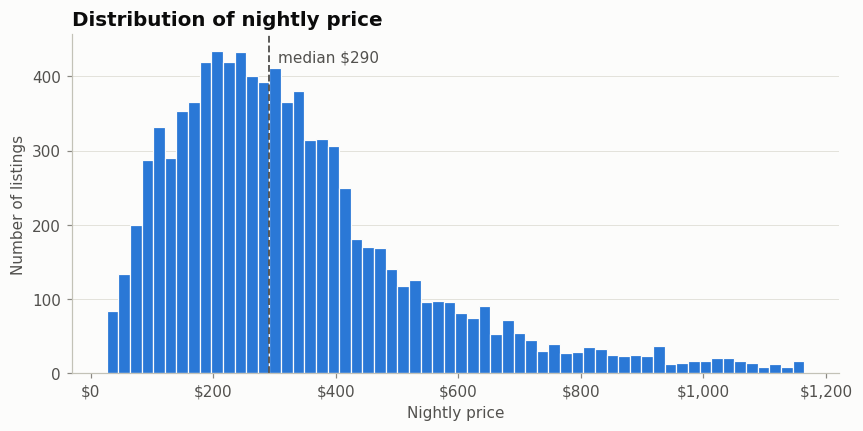

In [27]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(data["price"], bins=60, color=BLUE, edgecolor="#fcfcfb", linewidth=0.8)
med = data["price"].median()
ax.axvline(med, color=INK_2, linewidth=1.2, linestyle="--")
ax.annotate(f"median ${med:,.0f}", xy=(med, ax.get_ylim()[1] * 0.92), xytext=(6, 0),
            textcoords="offset points", color=INK_2)
ax.set_title("Distribution of nightly price")
ax.set_xlabel("Nightly price")
ax.set_ylabel("Number of listings")
ax.xaxis.set_major_formatter(dollars)
ax.grid(axis="x", visible=False)
plt.show()

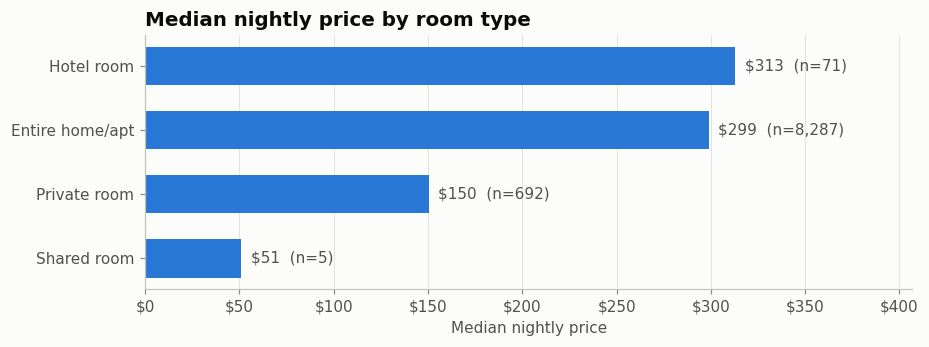

In [28]:
by_room = data.groupby("room_type")["price"].agg(["median", "count"]).sort_values("median")
fig, ax = plt.subplots(figsize=(9, 3))
bars = ax.barh(by_room.index, by_room["median"], color=BLUE, height=0.6)
for bar, (m, n) in zip(bars, by_room.values):
    ax.text(bar.get_width() + 5, bar.get_y() + bar.get_height() / 2,
            f"${m:,.0f}  (n={n:,.0f})", va="center", color=INK_2)
ax.set_title("Median nightly price by room type")
ax.set_xlabel("Median nightly price")
ax.xaxis.set_major_formatter(dollars)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, by_room["median"].max() * 1.3)
plt.show()

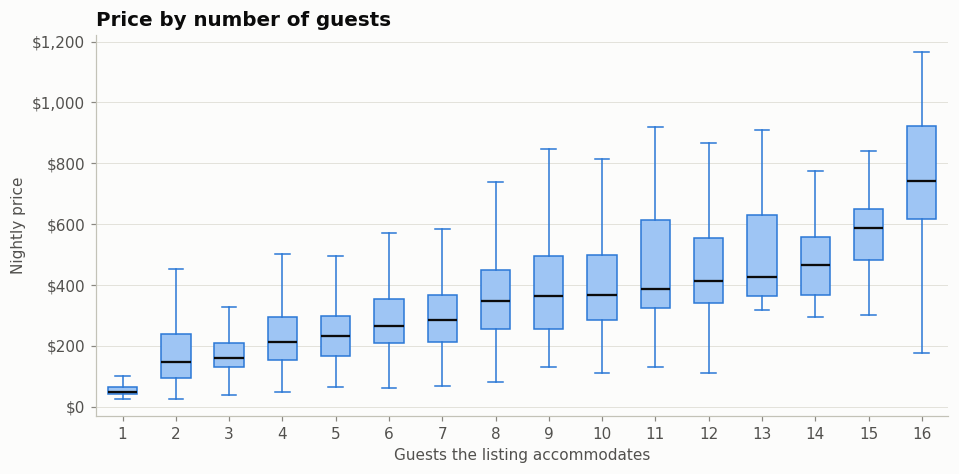

In [29]:
cap = data[data["accommodates"] <= 16]
labels = sorted(cap["accommodates"].unique())
groups = [cap.loc[cap["accommodates"] == k, "price"].values for k in labels]
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.boxplot(groups, tick_labels=labels, showfliers=False, widths=0.55, patch_artist=True,
           boxprops=dict(facecolor="#9ec5f4", edgecolor=BLUE, linewidth=1),
           medianprops=dict(color=INK, linewidth=1.5),
           whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE))
ax.set_title("Price by number of guests")
ax.set_xlabel("Guests the listing accommodates")
ax.set_ylabel("Nightly price")
ax.yaxis.set_major_formatter(dollars)
ax.grid(axis="x", visible=False)
plt.show()

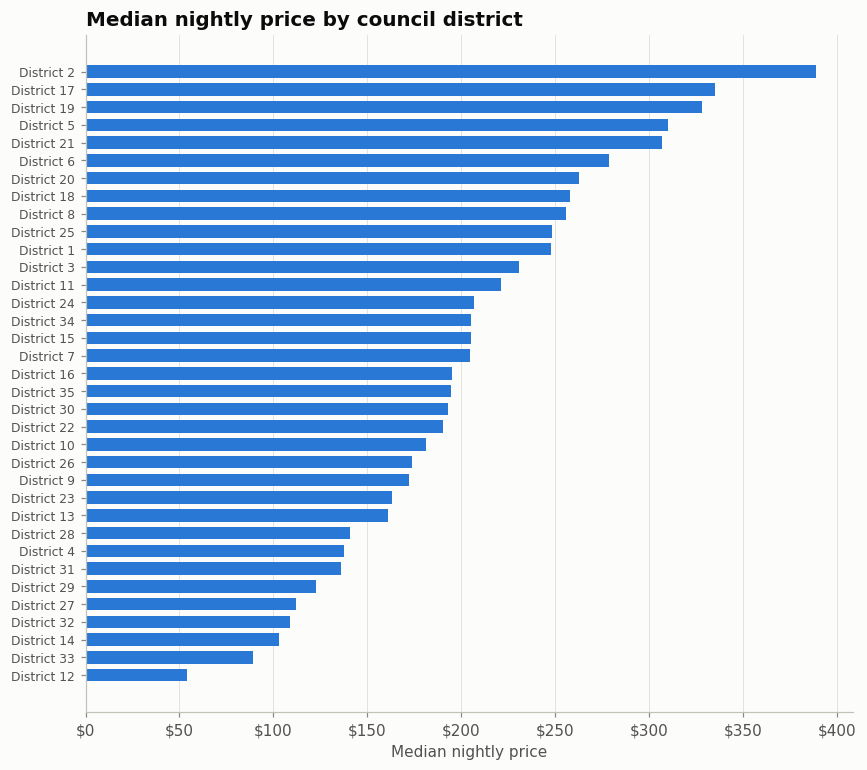

In [30]:
by_district = data.groupby("council_district")["price"].median().sort_values()
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh([f"District {d}" for d in by_district.index], by_district.values, color=BLUE, height=0.7)
ax.set_title("Median nightly price by council district")
ax.set_xlabel("Median nightly price")
ax.xaxis.set_major_formatter(dollars)
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=8)
plt.show()

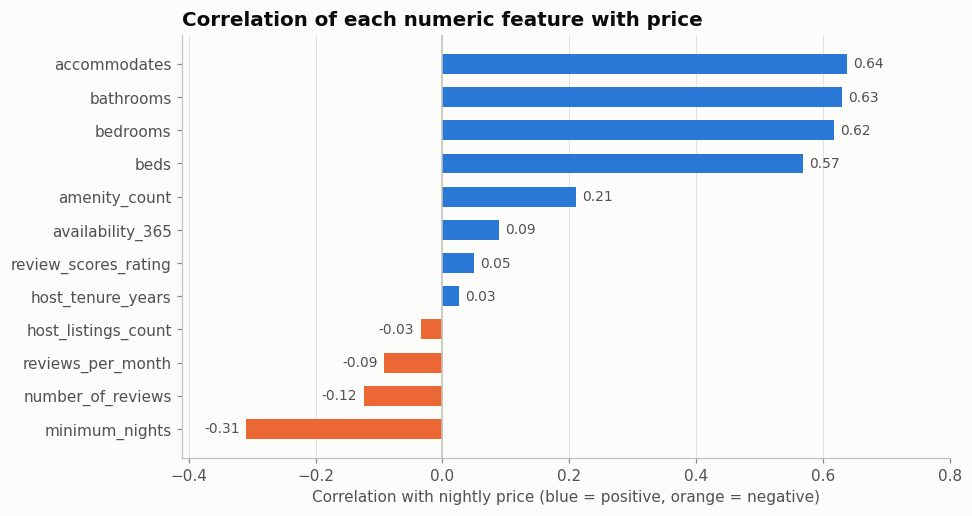

In [31]:
numeric_candidates = [
    "accommodates", "bedrooms", "beds", "bathrooms", "amenity_count",
    "review_scores_rating", "number_of_reviews", "reviews_per_month",
    "minimum_nights", "availability_365", "host_listings_count", "host_tenure_years",
]
corr = data[numeric_candidates + ["price"]].corr()["price"].drop("price").sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(corr.index, corr.values, color=[BLUE if v > 0 else ORANGE for v in corr.values], height=0.6)
ax.axvline(0, color=GRAY, linewidth=1)
for i, v in enumerate(corr.values):
    ax.text(v + (0.01 if v >= 0 else -0.01), i, f"{v:.2f}", va="center",
            ha="left" if v >= 0 else "right", color=INK_2, fontsize=9)
ax.set_title("Correlation of each numeric feature with price")
ax.set_xlabel("Correlation with nightly price (blue = positive, orange = negative)")
ax.set_xlim(min(-0.3, corr.min() - 0.1), max(0.8, corr.max() + 0.1))
ax.grid(axis="y", visible=False)
plt.show()

## 10. Predictors (X) and target (y)

**y** = nightly `price` (in dollars).

**X** = listing features a guest or host can see. Left out on purpose:
- `price_per_guest`, `estimated_revenue_l365d`
- IDs, names, free text, and dates.

In [32]:
numeric_features = [
    "accommodates", "bedrooms", "beds", "bathrooms", "amenity_count",
    "review_scores_rating", "number_of_reviews", "minimum_nights",
    "availability_365", "host_listings_count", "host_tenure_years",
]
flag_features = ["host_is_superhost", "has_license"]
categorical_features = ["room_type", "bathroom_type", "council_district"]
model_df = data[numeric_features + flag_features + categorical_features + ["price"]].dropna()
print(f"Rows used: {len(model_df):,} of {len(data):,} ({len(data) - len(model_df):,} dropped for missing values)")
room_counts = model_df["room_type"].value_counts()
rare_rooms = room_counts[room_counts < 30].index.tolist()
model_df = model_df[~model_df["room_type"].isin(rare_rooms)]
print(f"Excluded rare room types {rare_rooms}: {len(model_df):,} rows remain")
X = pd.get_dummies(
    model_df[numeric_features + flag_features + categorical_features],
    columns=categorical_features, drop_first=True, dtype=float,
)
X = X.astype(float)   
y = model_df["price"].astype(float)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("X:", X.shape, "| train:", X_train.shape[0], "| test:", X_test.shape[0])

Rows used: 7,904 of 9,055 (1,151 dropped for missing values)
Excluded rare room types ['Shared room']: 7,901 rows remain
X: (7901, 50) | train: 6320 | test: 1581


## 11. Simple linear regression

In [33]:
simple = sm.OLS(y_train, sm.add_constant(X_train[["accommodates"]])).fit()
print(simple.summary().tables[1])
simple_pred = simple.predict(sm.add_constant(X_test[["accommodates"]]))
b0, b1 = simple.params
print(f"\nprice ≈ ${b0:,.0f} + ${b1:,.0f} × guests")
print(f"Test R²: {r2_score(y_test, simple_pred):.3f}")

                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const           87.4785      4.039     21.660      0.000      79.561      95.396
accommodates    34.5000      0.499     69.169      0.000      33.522      35.478

price ≈ $87 + $34 × guests
Test R²: 0.395


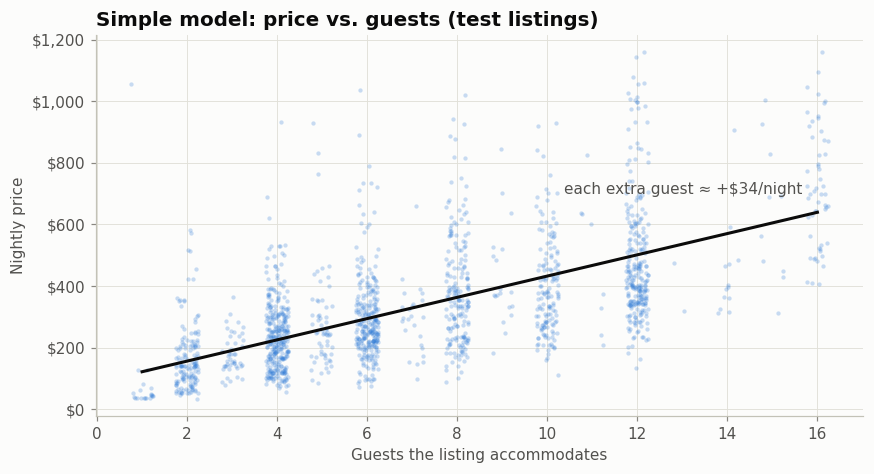

In [34]:
fig, ax = plt.subplots(figsize=(9, 4.5))
jitter = np.random.default_rng(0).uniform(-0.25, 0.25, len(X_test))
ax.scatter(X_test["accommodates"] + jitter, y_test, s=8, alpha=0.25, color=BLUE, linewidths=0)
xs = np.linspace(X_test["accommodates"].min(), X_test["accommodates"].max(), 50)
ax.plot(xs, b0 + b1 * xs, color=INK, linewidth=2)
ax.annotate(f"each extra guest ≈ +${b1:,.0f}/night", xy=(xs[-1], b0 + b1 * xs[-1]), xytext=(-10, 12),
            textcoords="offset points", ha="right", color=INK_2)
ax.set_title("Simple model: price vs. guests (test listings)")
ax.set_xlabel("Guests the listing accommodates")
ax.set_ylabel("Nightly price")
ax.yaxis.set_major_formatter(dollars)
plt.show()

## 12. Multiple linear regression

All predictors together. Each coefficient is the change in nightly price for a one-unit increase in that
feature **with every other feature held constant**.

In [35]:
multi = sm.OLS(y_train, sm.add_constant(X_train)).fit()
multi_pred = multi.predict(sm.add_constant(X_test))
print(multi.summary())

                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.565
Model:                            OLS   Adj. R-squared:                  0.561
Method:                 Least Squares   F-statistic:                     162.6
Date:                Mon, 16 Nov 2026   Prob (F-statistic):               0.00
Time:                        01:05:35   Log-Likelihood:                -39903.
No. Observations:                6320   AIC:                         7.991e+04
Df Residuals:                    6269   BIC:                         8.025e+04
Df Model:                          50                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                     11

In [36]:
def scores(pred):
    return {
        "R² (test)": r2_score(y_test, pred),
        "MAE (test)": mean_absolute_error(y_test, pred),
        "RMSE (test)": mean_squared_error(y_test, pred) ** 0.5,
    }

comparison = pd.DataFrame({"Simple (guests only)": scores(simple_pred),
                           "Multiple (all predictors)": scores(multi_pred)}).T
comparison.style.format({"R² (test)": "{:.3f}", "MAE (test)": "${:,.0f}", "RMSE (test)": "${:,.0f}"})

,R² (test),MAE (test),RMSE (test)
Simple (guests only),0.395,$114,$156
Multiple (all predictors),0.531,$99,$137


In [37]:
coefs = pd.DataFrame({
    "coef ($)": multi.params,
    "ci_low": multi.conf_int()[0],
    "ci_high": multi.conf_int()[1],
    "p_value": multi.pvalues,
}).drop("const")
coefs["significant (p<0.05)"] = coefs["p_value"] < 0.05

non_district = coefs[~coefs.index.str.startswith("council_district_")]
non_district.sort_values("p_value").style.format(
    {"coef ($)": "{:+,.2f}", "ci_low": "{:+,.2f}", "ci_high": "{:+,.2f}", "p_value": "{:.4f}"})

,coef ($),ci_low,ci_high,p_value,significant (p<0.05)
minimum_nights,-3.39,-3.72,-3.05,0.0000,True
bathrooms,+38.50,+32.82,+44.17,0.0000,True
bedrooms,+36.94,+31.04,+42.83,0.0000,True
accommodates,+11.18,+9.05,+13.30,0.0000,True
number_of_reviews,-0.10,-0.12,-0.07,0.0000,True
beds,-5.70,-7.62,-3.78,0.0000,True
host_tenure_years,+2.50,+1.51,+3.49,0.0000,True
has_license,+24.79,+14.45,+35.12,0.0000,True
amenity_count,+0.60,+0.32,+0.87,0.0000,True
room_type_Hotel room,+101.09,+46.50,+155.68,0.0003,True


Raw coefficients can't be compared with each other (a dollar per bedroom vs. a dollar per review).
To rank **impact**, scale each numeric coefficient by that feature's standard deviation (SD):
*how much price moves when the feature changes by a typical amount.* For yes/no and category features
the coefficient is already the dollar difference from the baseline.

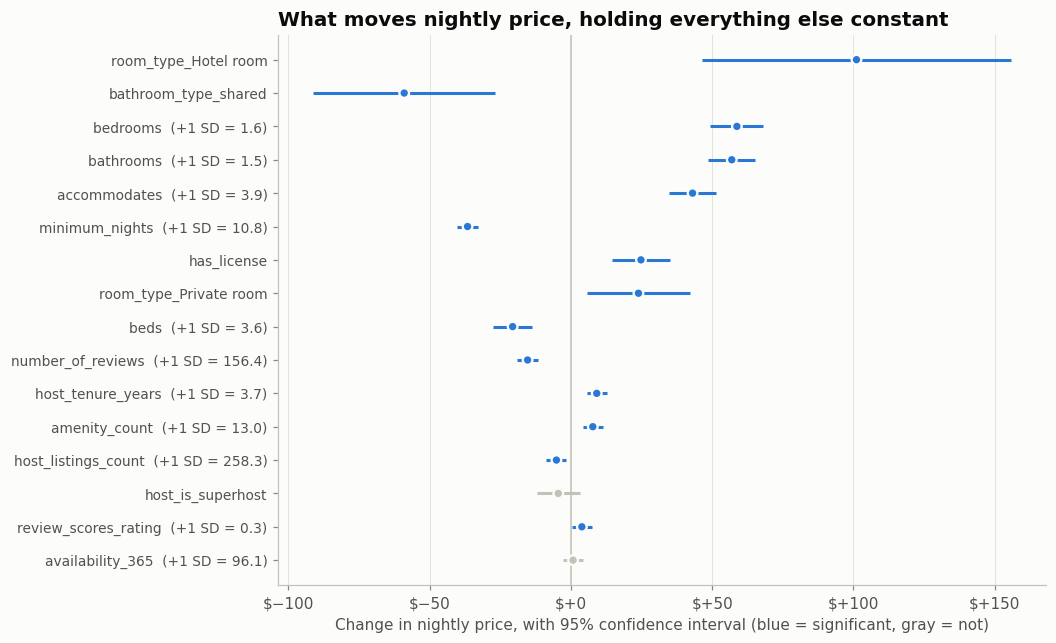

In [38]:
impact = non_district.copy()
sd = X_train[numeric_features].std()
for col in ["coef ($)", "ci_low", "ci_high"]:
    impact.loc[numeric_features, col] *= sd
impact["label"] = [f"{c}  (+1 SD = {sd[c]:,.1f})" if c in sd else c for c in impact.index]
impact = impact.reindex(impact["coef ($)"].abs().sort_values().index)

fig, ax = plt.subplots(figsize=(9, 6.5))
ypos = np.arange(len(impact))
colors = [BLUE if s else GRAY for s in impact["significant (p<0.05)"]]
ax.hlines(ypos, impact["ci_low"], impact["ci_high"], color=colors, linewidth=2)
ax.scatter(impact["coef ($)"], ypos, color=colors, s=40, zorder=3, edgecolor="#fcfcfb", linewidth=1.5)
ax.axvline(0, color=GRAY, linewidth=1)
ax.set_yticks(ypos, impact["label"], fontsize=9)
ax.set_title("What moves nightly price, holding everything else constant")
ax.set_xlabel("Change in nightly price, with 95% confidence interval (blue = significant, gray = not)")
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("${x:+,.0f}"))
ax.grid(axis="y", visible=False)
plt.show()

In [39]:
district = coefs[coefs.index.str.startswith("council_district_")]["coef ($)"].sort_values()
baseline = int(model_df["council_district"].min())
print(f"Districts vs. District {baseline}, for otherwise identical listings:")
print("\nMost expensive:"); print(district.tail(5).map("${:+,.0f}".format).to_string())
print("\nLeast expensive:"); print(district.head(5).map("${:+,.0f}".format).to_string())

Districts vs. District 1, for otherwise identical listings:

Most expensive:
council_district_6      $+5
council_district_17     $+9
council_district_25    $+26
council_district_23    $+27
council_district_19    $+75

Least expensive:
council_district_33    $-94
council_district_29    $-89
council_district_11    $-76
council_district_32    $-75
council_district_9     $-72


### Model checks

- **Actual vs. predicted**: points near the diagonal are good predictions.
- **Multicollinearity (VIF)**: guests, bedrooms, beds and bathrooms all measure size and move together.
  When VIF is above ~5, the model can't cleanly separate their individual effects, so treat those single
  coefficients with care (their combined effect is still reliable).

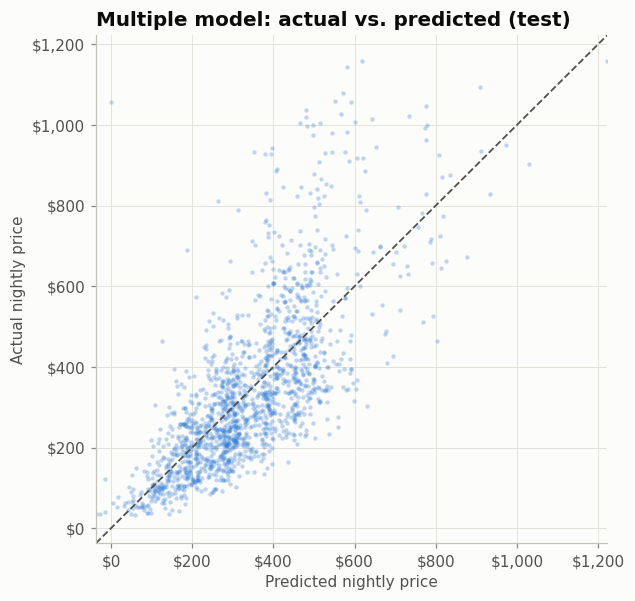

In [40]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(multi_pred, y_test, s=8, alpha=0.3, color=BLUE, linewidths=0)
lim = [min(0, multi_pred.min()), max(y_test.max(), multi_pred.max())]
ax.plot(lim, lim, color=INK_2, linewidth=1.2, linestyle="--")
ax.set_title("Multiple model: actual vs. predicted (test)")
ax.set_xlabel("Predicted nightly price")
ax.set_ylabel("Actual nightly price")
ax.xaxis.set_major_formatter(dollars); ax.yaxis.set_major_formatter(dollars)
ax.set_xlim(lim); ax.set_ylim(lim)
plt.show()

In [41]:
Xn = sm.add_constant(X_train[numeric_features + flag_features])
vif = pd.Series([variance_inflation_factor(Xn.values, i) for i in range(1, Xn.shape[1])],
                index=Xn.columns[1:], name="VIF").sort_values(ascending=False)
vif.round(1).to_frame()

,VIF
bedrooms,7.5
bathrooms,6.1
accommodates,5.7
beds,4.4
number_of_reviews,1.3
host_is_superhost,1.2
amenity_count,1.2
host_tenure_years,1.1
minimum_nights,1.1
review_scores_rating,1.1


## 13. Takeaways
**Model fit**
- Adding every other predictor raises that to about **53%**

**What raises price** 
- **Size** +$37 per bedroom, +$39 per bathroom, +$11 per extra guest.
- **Hotel rooms** cost about $101 more than an otherwise similar entire home.
- **Location:** District 19 is about $75 above District 1 for an identical listing
**What lowers price**
- A **shared bathroom** (about −$59).
- **Longer minimum stays**: about −$3.40 per extra required night, so 30-night rentals are much cheaper per night.
- Many **reviews** and very large **host portfolios** go with slightly lower prices.
**No measurable effect:** superhost status and days available per year.